# Подготовка данных BTCUSDT

Источник: официальный архив Binance.
Рынок: Spot.
Тип данных: отдельные сделки (trades).
Период: январь–март 2020.

Январь–февраль используются для разработки и настройки.
Март — для отложенной проверки.

Исследование проверяет методы Andersen–Bondarenko на новом рынке,
а не воспроизводит Flash Crash 2010.

In [28]:
from pathlib import Path
import pandas as pd
import numpy as np

cwd = Path.cwd()

if (cwd / "requirements.txt").exists():
    ROOT = cwd
elif (cwd.parent / "requirements.txt").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError("Не найден корень проекта")

RAW = ROOT / "data" / "raw" / "binance"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

MONTHS = ["2020-01", "2020-02", "2020-03"]

files = {
    month: RAW / f"BTCUSDT-trades-{month}.csv"
    for month in MONTHS
}

for month, path in files.items():
    if not path.exists():
        raise FileNotFoundError(f"Не найден файл: {path.name}")

    print(f"{month}: {path.name} — {path.stat().st_size / 1_000_000:.1f} MB")

2020-01: BTCUSDT-trades-2020-01.csv — 1078.0 MB
2020-02: BTCUSDT-trades-2020-02.csv — 1294.7 MB
2020-03: BTCUSDT-trades-2020-03.csv — 2051.6 MB


In [29]:
for month, path in files.items():
    preview = pd.read_csv(
        path,
        header=None,
        nrows=5,
    )

    print(f"\n{'=' * 60}")
    print(f"Месяц: {month}")
    print(f"Количество колонок: {preview.shape[1]}")
    print(preview.to_string(index=False, header=False))


Месяц: 2020-01
Количество колонок: 7
222472783 7195.24 0.001500   10.792860 1577836800594  True True
222472784 7196.25 0.022706  163.398053 1577836800862 False True
222472785 7196.25 0.099650  717.106312 1577836800862 False True
222472786 7196.25 0.001543   11.103814 1577836800998 False True
222472787 7195.25 0.400000 2878.100000 1577836801503  True True

Месяц: 2020-02
Количество колонок: 7
237367441 9351.71 0.043982   411.306909 1580515200518  True True
237367442 9351.71 0.001413    13.213966 1580515200580  True True
237367443 9352.86 0.001236    11.560135 1580515200690 False True
237367444 9352.85 0.001976    18.481232 1580515201148  True True
237367445 9352.00 1.214703 11359.902456 1580515201176 False True

Месяц: 2020-03
Количество колонок: 7
255204870 8523.61 0.000013    0.110807 1583020800003 True True
255204871 8523.50 0.001400   11.932900 1583020800003 True True
255204872 8523.43 0.010225   87.152072 1583020800003 True True
255204873 8523.21 0.012771  108.849915 1583020800003

## Аудит исходных сделок

Проверяем:
- пропуски и недопустимые значения;
- положительность цены и объёма;
- порядок времени и идентификаторов сделок;
- разрывы идентификаторов;
- соответствие дат месяцу файла.

Читаем CSV порциями. Исходные данные не изменяем.

In [30]:
import numpy as np

COLUMNS = [
    "trade_id",
    "price",
    "qty",
    "quote_qty",
    "time",
    "is_buyer_maker",
    "is_best_match",
]

DTYPES = {
    "trade_id": "int64",
    "price": "float64",
    "qty": "float64",
    "quote_qty": "float64",
    "time": "int64",
    "is_buyer_maker": "string",
    "is_best_match": "string",
}


def audit_month(path, month, chunksize=500_000):
    start = pd.Timestamp(f"{month}-01", tz="UTC")
    end = start + pd.offsets.MonthBegin(1)

    result = {
        "month": month,
        "rows": 0,
        "missing_rows": 0,
        "invalid_numeric_rows": 0,
        "invalid_flag_rows": 0,
        "outside_month_rows": 0,
        "id_non_increasing": 0,
        "id_gap_events": 0,
        "time_backwards": 0,
        "volume_btc": 0.0,
        "quote_volume_usdt": 0.0,
        "min_price": np.inf,
        "max_price": -np.inf,
        "first_id": None,
        "last_id": None,
        "first_time_ms": None,
        "last_time_ms": None,
    }

    previous_id = None
    previous_time = None

    reader = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
        dtype=DTYPES,
        chunksize=chunksize,
    )

    for number, chunk in enumerate(reader, start=1):
        if chunk.empty:
            continue

        numeric = chunk[["price", "qty", "quote_qty"]]
        finite = pd.Series(
            np.isfinite(numeric.to_numpy()).all(axis=1),
            index=chunk.index,
        )
        positive = numeric.gt(0).all(axis=1)

        flags_valid = pd.Series(True, index=chunk.index)

        for column in ["is_buyer_maker", "is_best_match"]:
            values = chunk[column].str.strip().str.lower()
            flags_valid &= values.isin(["true", "false"])

        timestamps = pd.to_datetime(
            chunk["time"],
            unit="ms",
            utc=True,
            errors="coerce",
        )

        id_diff = chunk["trade_id"].diff()
        time_diff = chunk["time"].diff()

        if previous_id is not None:
            id_diff.iloc[0] = int(chunk["trade_id"].iloc[0]) - previous_id
            time_diff.iloc[0] = int(chunk["time"].iloc[0]) - previous_time

        if result["first_id"] is None:
            result["first_id"] = int(chunk["trade_id"].iloc[0])
            result["first_time_ms"] = int(chunk["time"].iloc[0])

        result["rows"] += len(chunk)
        result["missing_rows"] += int(chunk.isna().any(axis=1).sum())
        result["invalid_numeric_rows"] += int((~finite | ~positive).sum())
        result["invalid_flag_rows"] += int((~flags_valid).sum())
        result["outside_month_rows"] += int(
            (~timestamps.ge(start) | ~timestamps.lt(end)).sum()
        )
        result["id_non_increasing"] += int(id_diff.le(0).sum())
        result["id_gap_events"] += int(id_diff.gt(1).sum())
        result["time_backwards"] += int(time_diff.lt(0).sum())

        result["volume_btc"] += float(chunk["qty"].sum())
        result["quote_volume_usdt"] += float(chunk["quote_qty"].sum())
        result["min_price"] = min(result["min_price"], chunk["price"].min())
        result["max_price"] = max(result["max_price"], chunk["price"].max())

        previous_id = int(chunk["trade_id"].iloc[-1])
        previous_time = int(chunk["time"].iloc[-1])

        result["last_id"] = previous_id
        result["last_time_ms"] = previous_time

        if number % 10 == 0:
            print(f"{month}: проверено {result['rows']:,} строк")

    if result["rows"] == 0:
        raise ValueError(f"Пустой файл: {path.name}")

    return result

In [31]:
results = []

for month, path in files.items():
    print(f"\nПроверяем {month}...")
    results.append(audit_month(path, month))
    print(f"{month}: завершено")

audit = pd.DataFrame(results)

audit["first_timestamp_utc"] = pd.to_datetime(
    audit["first_time_ms"], unit="ms", utc=True
)
audit["last_timestamp_utc"] = pd.to_datetime(
    audit["last_time_ms"], unit="ms", utc=True
)

audit_path = PROCESSED / "binance_monthly_audit.csv"
audit.to_csv(audit_path, index=False)

print("\nИТОГ:")
print(audit.to_string(index=False))
print("\nОтчёт сохранён:", audit_path.name)


Проверяем 2020-01...
2020-01: проверено 5,000,000 строк
2020-01: проверено 10,000,000 строк
2020-01: проверено 14,894,658 строк
2020-01: завершено

Проверяем 2020-02...
2020-02: проверено 5,000,000 строк
2020-02: проверено 10,000,000 строк
2020-02: проверено 15,000,000 строк
2020-02: завершено

Проверяем 2020-03...
2020-03: проверено 5,000,000 строк
2020-03: проверено 10,000,000 строк
2020-03: проверено 15,000,000 строк
2020-03: проверено 20,000,000 строк
2020-03: проверено 25,000,000 строк
2020-03: завершено

ИТОГ:
  month     rows  missing_rows  invalid_numeric_rows  invalid_flag_rows  outside_month_rows  id_non_increasing  id_gap_events  time_backwards   volume_btc  quote_volume_usdt  min_price  max_price  first_id   last_id  first_time_ms  last_time_ms              first_timestamp_utc               last_timestamp_utc
2020-01 14894658             0                     0                  0                   0                  0              0               0 1.691323e+06       1.418

## Построение минутных баров

Для каждой минуты UTC:
- close — цена последней сделки;
- volume_btc — сумма qty;
- trade_count — число сделок.

Бар доступен после завершения минуты.
Проверяем сохранение общего объёма и числа сделок.
Пустые минуты отмечаем явно, цену автоматически не заполняем.

In [32]:
def build_minute_bars(path, month, chunksize=500_000):
    parts = []

    reader = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
        usecols=["trade_id", "price", "qty", "time"],
        dtype={
            "trade_id": "int64",
            "price": "float64",
            "qty": "float64",
            "time": "int64",
        },
        chunksize=chunksize,
    )

    for number, chunk in enumerate(reader, start=1):
        chunk["minute_start"] = pd.to_datetime(
            chunk["time"],
            unit="ms",
            utc=True,
        ).dt.floor("min")

        part = chunk.groupby("minute_start", sort=False).agg(
            close=("price", "last"),
            volume_btc=("qty", "sum"),
            trade_count=("trade_id", "size"),
        )

        parts.append(part)

        if number % 10 == 0:
            print(f"{month}: обработано порций — {number}")

    if not parts:
        raise ValueError(f"Пустой файл: {path.name}")

    combined = pd.concat(parts)

    bars = combined.groupby(level="minute_start", sort=True).agg(
        close=("close", "last"),
        volume_btc=("volume_btc", "sum"),
        trade_count=("trade_count", "sum"),
    )

    start = pd.Timestamp(f"{month}-01", tz="UTC")
    end = start + pd.offsets.MonthBegin(1)

    minute_grid = pd.date_range(
        start=start,
        end=end,
        freq="min",
        inclusive="left",
        name="minute_start",
    )

    bars = bars.reindex(minute_grid)

    bars["volume_btc"] = bars["volume_btc"].fillna(0.0)
    bars["trade_count"] = bars["trade_count"].fillna(0).astype("int64")
    bars["available_at"] = bars.index + pd.Timedelta(minutes=1)

    return bars.reset_index()

In [33]:
monthly_bars = []
bar_checks = []

audit_by_month = audit.set_index("month")

for month, path in files.items():
    print(f"\nСтроим бары за {month}...")

    bars = build_minute_bars(path, month)
    reference = audit_by_month.loc[month]

    expected_volume = float(reference["volume_btc"])
    actual_volume = float(bars["volume_btc"].sum())

    expected_count = int(reference["rows"])
    actual_count = int(bars["trade_count"].sum())

    if actual_count != expected_count:
        raise AssertionError(
            f"{month}: потеряно или добавлено число сделок"
        )

    if not np.isclose(
        actual_volume,
        expected_volume,
        rtol=1e-10,
        atol=1e-8,
    ):
        raise AssertionError(
            f"{month}: не сохранился объём"
        )

    empty = bars["trade_count"].eq(0)

    if not bars.loc[~empty, "close"].notna().all():
        raise AssertionError(
            f"{month}: отсутствует close у непустой минуты"
        )

    if not bars.loc[empty, "close"].isna().all():
        raise AssertionError(
            f"{month}: у пустой минуты неожиданно есть close"
        )

    monthly_bars.append(bars)

    bar_checks.append({
        "month": month,
        "minutes": len(bars),
        "empty_minutes": int(empty.sum()),
        "trade_count": actual_count,
        "volume_btc": actual_volume,
        "volume_difference": actual_volume - expected_volume,
    })

minute_bars = pd.concat(monthly_bars, ignore_index=True)

if not minute_bars["minute_start"].is_unique:
    raise AssertionError("Повторяются минутные метки")

if not minute_bars["minute_start"].is_monotonic_increasing:
    raise AssertionError("Нарушен порядок минут")

checks_table = pd.DataFrame(bar_checks)

print("\nПРОВЕРКИ АГРЕГАЦИИ:")
print(checks_table.to_string(index=False))

print("\nПЕРВЫЕ БАРЫ:")
print(minute_bars.head(10).to_string(index=False))


Строим бары за 2020-01...
2020-01: обработано порций — 10
2020-01: обработано порций — 20
2020-01: обработано порций — 30

Строим бары за 2020-02...
2020-02: обработано порций — 10
2020-02: обработано порций — 20
2020-02: обработано порций — 30

Строим бары за 2020-03...
2020-03: обработано порций — 10
2020-03: обработано порций — 20
2020-03: обработано порций — 30
2020-03: обработано порций — 40
2020-03: обработано порций — 50

ПРОВЕРКИ АГРЕГАЦИИ:
  month  minutes  empty_minutes  trade_count   volume_btc  volume_difference
2020-01    44640              0     14894658 1.691323e+06       0.000000e+00
2020-02    41760            414     17837429 1.609726e+06       2.328306e-10
2020-03    44640            128     28381746 3.789769e+06      -2.328306e-09

ПЕРВЫЕ БАРЫ:
             minute_start   close  volume_btc  trade_count              available_at
2020-01-01 00:00:00+00:00 7186.68   51.642812          493 2020-01-01 00:01:00+00:00
2020-01-01 00:01:00+00:00 7184.03    7.248148         

In [34]:
bars_path = PROCESSED / "btcusdt_1min_2020_q1.csv"
checks_path = PROCESSED / "minute_bars_audit.csv"

minute_bars.to_csv(bars_path, index=False)
checks_table.to_csv(checks_path, index=False)

print("Сохранены:")
print(bars_path.name)
print(checks_path.name)

Сохранены:
btcusdt_1min_2020_q1.csv
minute_bars_audit.csv


In [35]:
empty = minute_bars["trade_count"].eq(0)

run_id = empty.ne(empty.shift(fill_value=False)).cumsum()

gap_rows = []

for _, block in minute_bars.loc[empty].groupby(run_id.loc[empty]):
    gap_rows.append({
        "start_utc": block["minute_start"].iloc[0],
        "end_utc_exclusive": block["available_at"].iloc[-1],
        "duration_minutes": len(block),
    })

gaps = pd.DataFrame(
    gap_rows,
    columns=[
        "start_utc",
        "end_utc_exclusive",
        "duration_minutes",
    ],
)

print("ИНТЕРВАЛЫ БЕЗ СДЕЛОК:")
print(gaps.to_string(index=False))

print("\nВсего пустых минут:", int(empty.sum()))

gaps.to_csv(
    PROCESSED / "empty_minute_intervals.csv",
    index=False,
)

ИНТЕРВАЛЫ БЕЗ СДЕЛОК:
                start_utc         end_utc_exclusive  duration_minutes
2020-02-09 02:00:00+00:00 2020-02-09 03:00:00+00:00                60
2020-02-19 11:36:00+00:00 2020-02-19 17:30:00+00:00               354
2020-03-04 09:22:00+00:00 2020-03-04 11:30:00+00:00               128

Всего пустых минут: 542


## Минутная tick-rule классификация

Направление определяется изменением close между последовательными
непустыми минутами. При неизменной цене переносится последний
установленный знак.

Пустые минуты не классифицируются.
После остановки торгов используем последнюю наблюдавшуюся цену.

Начальные минуты до первого определимого знака исключаются
из расчёта VPIN; их объём учитывается отдельно.

Размер бакета фиксируется по январю–февралю 2020.
Март не используется для настройки.

In [36]:
classified = minute_bars.copy()

observed = classified["trade_count"].gt(0)

observed_close = classified.loc[observed, "close"]
price_change = observed_close.diff()

observed_sign = (
    np.sign(price_change)
    .replace(0, np.nan)
    .ffill()
)

classified["tick_sign"] = pd.Series(
    pd.NA,
    index=classified.index,
    dtype="Int8",
)

classified.loc[observed, "tick_sign"] = observed_sign.astype("Int8")

classified["is_classified"] = (
    observed & classified["tick_sign"].notna()
)

classified["buy_volume_btc"] = np.where(
    classified["tick_sign"].eq(1).fillna(False),
    classified["volume_btc"],
    0.0,
)

classified["sell_volume_btc"] = np.where(
    classified["tick_sign"].eq(-1).fillna(False),
    classified["volume_btc"],
    0.0,
)

unclassified = observed & ~classified["is_classified"]

excluded_volume = float(
    classified.loc[unclassified, "volume_btc"].sum()
)

eligible_volume = float(
    classified.loc[classified["is_classified"], "volume_btc"].sum()
)

assigned_volume = float(
    classified["buy_volume_btc"].sum()
    + classified["sell_volume_btc"].sum()
)

assert np.isclose(
    eligible_volume,
    assigned_volume,
    rtol=1e-10,
    atol=1e-8,
)

assert classified.loc[
    ~observed, "tick_sign"
].isna().all()

assert classified.loc[
    classified["is_classified"], "tick_sign"
].isin([-1, 1]).all()

print("Непустых неклассифицированных минут:", int(unclassified.sum()))
print("Исключённый начальный объём, BTC:", excluded_volume)
print("Классифицированный объём, BTC:", eligible_volume)
print("Проверка распределения объёма: OK")

print(
    classified[
        [
            "minute_start",
            "close",
            "volume_btc",
            "tick_sign",
            "buy_volume_btc",
            "sell_volume_btc",
        ]
    ].head(10).to_string(index=False)
)

Непустых неклассифицированных минут: 1
Исключённый начальный объём, BTC: 51.642812
Классифицированный объём, BTC: 7090766.562659
Проверка распределения объёма: OK
             minute_start   close  volume_btc  tick_sign  buy_volume_btc  sell_volume_btc
2020-01-01 00:00:00+00:00 7186.68   51.642812       <NA>        0.000000         0.000000
2020-01-01 00:01:00+00:00 7184.03    7.248148         -1        0.000000         7.248148
2020-01-01 00:02:00+00:00 7182.43   11.681677         -1        0.000000        11.681677
2020-01-01 00:03:00+00:00 7185.94   10.025391          1       10.025391         0.000000
2020-01-01 00:04:00+00:00 7179.78   14.911105         -1        0.000000        14.911105
2020-01-01 00:05:00+00:00 7179.99   12.463243          1       12.463243         0.000000
2020-01-01 00:06:00+00:00 7182.00    3.573774          1        3.573774         0.000000
2020-01-01 00:07:00+00:00 7183.66   14.470782          1       14.470782         0.000000
2020-01-01 00:08:00+00:00 7

In [37]:
train_mask = classified["minute_start"].lt(
    pd.Timestamp("2020-03-01", tz="UTC")
)

train_daily_volume = (
    classified.loc[train_mask]
    .set_index("minute_start")["volume_btc"]
    .resample("D")
    .sum()
)

TARGET_BUCKETS_PER_DAY = 50
VPIN_WINDOW = 50

mean_daily_volume = float(train_daily_volume.mean())
BUCKET_VOLUME_BTC = mean_daily_volume / TARGET_BUCKETS_PER_DAY

assert len(train_daily_volume) == 60
assert BUCKET_VOLUME_BTC > 0

print("Дней для калибровки:", len(train_daily_volume))
print("Средний дневной объём, BTC:", round(mean_daily_volume, 6))
print("Размер бакета, BTC:", round(BUCKET_VOLUME_BTC, 6))
print("Окно VPIN, бакетов:", VPIN_WINDOW)

Дней для калибровки: 60
Средний дневной объём, BTC: 55017.488206
Размер бакета, BTC: 1100.349764
Окно VPIN, бакетов: 50


In [50]:
import json

config = {
    "symbol": "BTCUSDT",
    "market": "Binance Spot",
    "data_type": "trades",
    "timezone": "UTC",
    "train_start": "2020-01-01",
    "train_end_exclusive": "2020-03-01",
    "test_start": "2020-03-01",
    "test_end_exclusive": "2020-04-01",
    "time_bar_seconds": 60,
    "target_buckets_per_day": TARGET_BUCKETS_PER_DAY,
    "bucket_volume_btc": BUCKET_VOLUME_BTC,
    "vpin_window": VPIN_WINDOW,
    "initial_unclassified_volume_btc": excluded_volume,
    "zero_price_change_rule": "carry last established sign",
    "empty_minute_rule": "no sign and no volume",
    "reopening_rule": "compare with last observed close",
    "zip_checksum_status": "verified",
}

classified.to_csv(
    PROCESSED / "btcusdt_1min_classified_2020_q1.csv",
    index=False,
)

with (ROOT / "research_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

print("Классифицированные бары и параметры сохранены.")

Классифицированные бары и параметры сохранены.


## Объёмные бакеты и базовый TR-VPIN

Бакеты формируются непрерывно по всей выборке.
Объём минуты при необходимости разделяется между бакетами.
Все части минуты сохраняют её tick-rule знак.

Последний неполный бакет сохраняется для контроля объёма,
но не включается в VPIN.

Время доступности результата — конец последней исходной минуты.
VPIN рассчитывается только после накопления 50 полных бакетов.

In [39]:
import sys
import importlib

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.tr_vpin as tr_vpin_module

importlib.reload(tr_vpin_module)

buckets = tr_vpin_module.build_volume_buckets(
    classified=classified,
    bucket_volume=BUCKET_VOLUME_BTC,
)

vpin = tr_vpin_module.calculate_tr_vpin(
    buckets=buckets,
    bucket_volume=BUCKET_VOLUME_BTC,
    window=VPIN_WINDOW,
)

print("Бакеты построены.")

Бакеты построены.


In [40]:
source_volume = classified.loc[
    classified["is_classified"], "volume_btc"
].sum()

bucketed_volume = buckets["volume_btc"].sum()

source_buy = classified["buy_volume_btc"].sum()
source_sell = classified["sell_volume_btc"].sum()

complete = buckets["is_complete"]
partial = buckets.loc[~complete]

assert np.isclose(
    source_volume, bucketed_volume,
    rtol=1e-10, atol=1e-8,
)

assert np.isclose(
    source_buy, buckets["buy_volume_btc"].sum(),
    rtol=1e-10, atol=1e-8,
)

assert np.isclose(
    source_sell, buckets["sell_volume_btc"].sum(),
    rtol=1e-10, atol=1e-8,
)

assert np.allclose(
    buckets.loc[complete, "volume_btc"],
    BUCKET_VOLUME_BTC,
    rtol=1e-10,
    atol=1e-8,
)

assert len(partial) <= 1

if not partial.empty:
    assert partial.index[0] == buckets.index[-1]
    assert 0 < partial["volume_btc"].iloc[0] < BUCKET_VOLUME_BTC

assert vpin["available_at"].is_monotonic_increasing

tolerance = 1e-10

assert vpin["oi"].between(
    -tolerance, 1 + tolerance
).all()

assert vpin["tr_vpin"].dropna().between(
    -tolerance, 1 + tolerance
).all()

expected_valid = max(0, len(vpin) - VPIN_WINDOW + 1)

assert vpin["tr_vpin"].notna().sum() == expected_valid

summary = pd.Series({
    "complete_buckets": int(complete.sum()),
    "partial_buckets": len(partial),
    "partial_volume_btc": float(partial["volume_btc"].sum()),
    "source_volume_btc": source_volume,
    "bucketed_volume_btc": bucketed_volume,
    "volume_difference": bucketed_volume - source_volume,
    "valid_vpin_values": int(vpin["tr_vpin"].notna().sum()),
})

print("ПРОВЕРКИ: OK\n")
print(summary.to_string())

ПРОВЕРКИ: OK

complete_buckets       6.444000e+03
partial_buckets        1.000000e+00
partial_volume_btc     1.126827e+02
source_volume_btc      7.090767e+06
bucketed_volume_btc    7.090767e+06
volume_difference      9.313226e-10
valid_vpin_values      6.395000e+03


In [41]:
print("ПЕРВЫЕ 5 БАКЕТОВ:")
print(buckets.head(5).to_string(index=False))

print("\nПЕРВЫЕ 5 ДОСТУПНЫХ ЗНАЧЕНИЙ VPIN:")
print(
    vpin.loc[
        vpin["tr_vpin"].notna(),
        ["bucket_id", "available_at", "oi", "tr_vpin"],
    ].head(5).to_string(index=False)
)

buckets.to_csv(
    PROCESSED / "btcusdt_tr_buckets_2020_q1.csv",
    index=False,
)

vpin.to_csv(
    PROCESSED / "btcusdt_tr_vpin_2020_q1.csv",
    index=False,
)

print("\nРезультаты сохранены.")

ПЕРВЫЕ 5 БАКЕТОВ:
 bucket_id       first_source_minute              available_at  buy_volume_btc  sell_volume_btc  is_complete  volume_btc
         0 2020-01-01 00:01:00+00:00 2020-01-01 01:37:00+00:00      577.402121       522.947643         True 1100.349764
         1 2020-01-01 01:36:00+00:00 2020-01-01 03:11:00+00:00      582.167720       518.182044         True 1100.349764
         2 2020-01-01 03:10:00+00:00 2020-01-01 05:08:00+00:00      626.824496       473.525268         True 1100.349764
         3 2020-01-01 05:07:00+00:00 2020-01-01 07:19:00+00:00      562.111717       538.238047         True 1100.349764
         4 2020-01-01 07:18:00+00:00 2020-01-01 08:47:00+00:00      363.799923       736.549841         True 1100.349764

ПЕРВЫЕ 5 ДОСТУПНЫХ ЗНАЧЕНИЙ VPIN:
 bucket_id              available_at       oi  tr_vpin
        49 2020-01-03 02:57:00+00:00 0.269888 0.185416
        50 2020-01-03 03:52:00+00:00 0.167933 0.187784
        51 2020-01-03 04:18:00+00:00 0.574502 0.198111
 

In [42]:
first_window = vpin.iloc[:VPIN_WINDOW]

manual_oi = (
    first_window["buy_volume_btc"]
    - first_window["sell_volume_btc"]
).abs() / BUCKET_VOLUME_BTC

manual_first_vpin = manual_oi.sum() / VPIN_WINDOW
calculated_first_vpin = vpin["tr_vpin"].iloc[VPIN_WINDOW - 1]

assert np.isclose(
    manual_first_vpin,
    calculated_first_vpin,
    rtol=1e-12,
    atol=1e-12,
)

print("Первый VPIN по формуле:", manual_first_vpin)
print("Первый VPIN из функции:", calculated_first_vpin)
print("Совпадение: OK")

Первый VPIN по формуле: 0.1854155028081191
Первый VPIN из функции: 0.1854155028081191
Совпадение: OK


In [43]:
sample = classified.loc[
    classified["is_classified"],
    ["volume_btc", "tick_sign"],
].copy()

volume_end = sample["volume_btc"].cumsum().to_numpy()
volume_start = volume_end - sample["volume_btc"].to_numpy()
signs = sample["tick_sign"].to_numpy(dtype=int)

reference_rows = []

for bucket_id in range(5):
    left = bucket_id * BUCKET_VOLUME_BTC
    right = (bucket_id + 1) * BUCKET_VOLUME_BTC

    overlap = np.maximum(
        0.0,
        np.minimum(volume_end, right)
        - np.maximum(volume_start, left),
    )

    reference_rows.append({
        "bucket_id": bucket_id,
        "reference_buy": overlap[signs == 1].sum(),
        "reference_sell": overlap[signs == -1].sum(),
    })

reference = pd.DataFrame(reference_rows)

comparison = buckets.head(5).merge(
    reference,
    on="bucket_id",
    validate="one_to_one",
)

comparison["buy_difference"] = (
    comparison["buy_volume_btc"] - comparison["reference_buy"]
)

comparison["sell_difference"] = (
    comparison["sell_volume_btc"] - comparison["reference_sell"]
)

assert np.allclose(
    comparison["buy_volume_btc"],
    comparison["reference_buy"],
    rtol=1e-10,
    atol=1e-8,
)

assert np.allclose(
    comparison["sell_volume_btc"],
    comparison["reference_sell"],
    rtol=1e-10,
    atol=1e-8,
)

print(
    comparison[
        ["bucket_id", "buy_difference", "sell_difference"]
    ].to_string(index=False)
)

print("\nНезависимая проверка первых пяти бакетов: OK")

 bucket_id  buy_difference  sell_difference
         0    1.136868e-13    -1.136868e-13
         1    3.410605e-13    -4.547474e-13
         2    1.136868e-12    -6.821210e-13
         3    5.684342e-13    -6.821210e-13
         4    6.821210e-13    -1.932676e-12

Независимая проверка первых пяти бакетов: OK


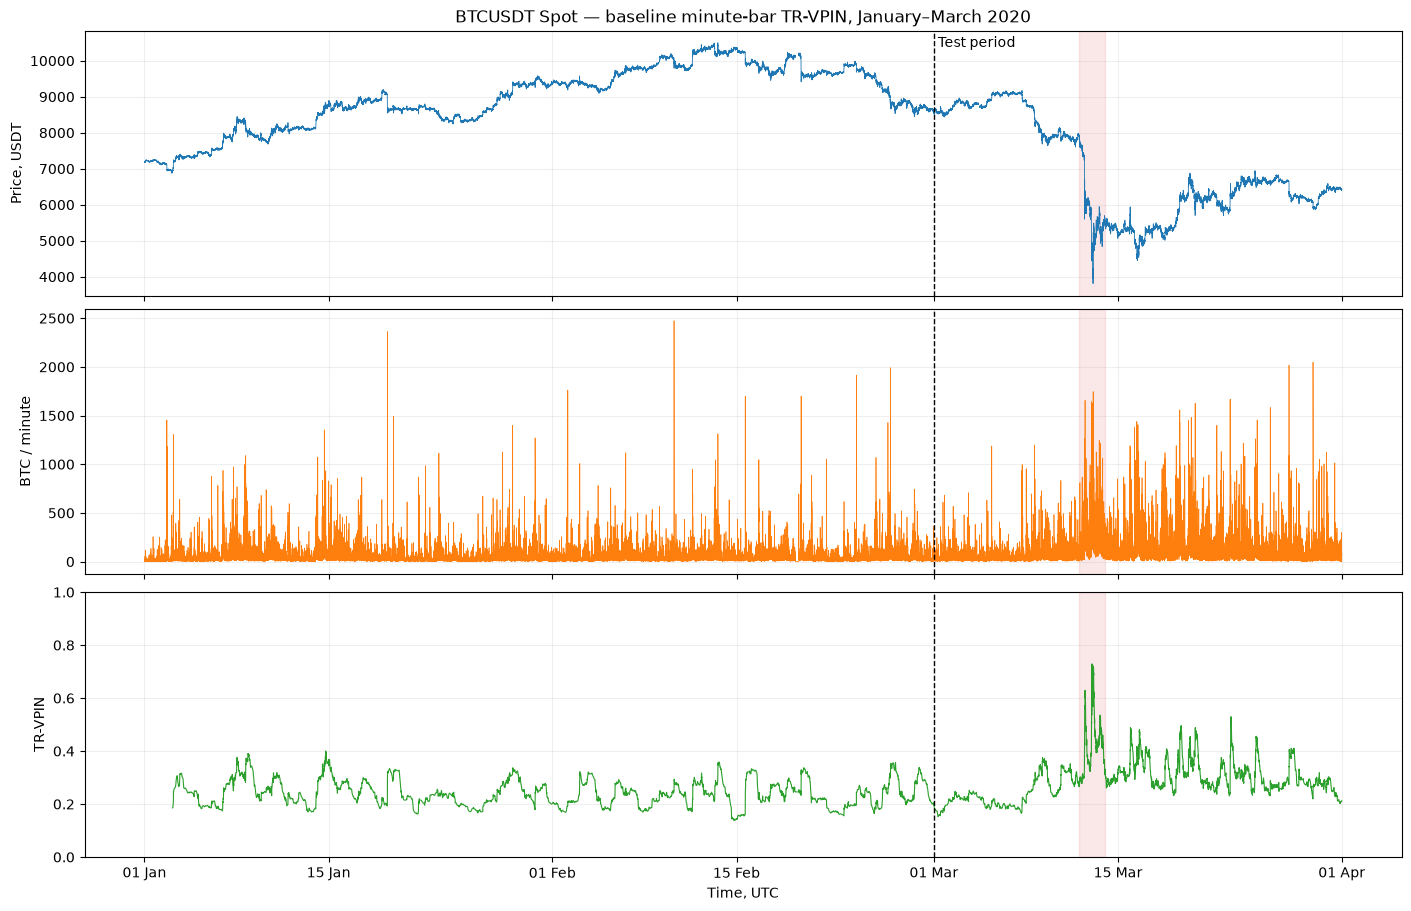

График сохранён: baseline_tr_vpin_2020_q1.png


In [44]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

valid_vpin = vpin.loc[vpin["tr_vpin"].notna()]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 9),
    sharex=True,
    layout="constrained",
)

axes[0].plot(
    minute_bars["available_at"],
    minute_bars["close"],
    linewidth=0.6,
)
axes[0].set_ylabel("Price, USDT")
axes[0].set_title(
    "BTCUSDT Spot — baseline minute-bar TR-VPIN, January–March 2020"
)

axes[1].plot(
    minute_bars["available_at"],
    minute_bars["volume_btc"],
    linewidth=0.5,
    color="tab:orange",
)
axes[1].set_ylabel("BTC / minute")

axes[2].plot(
    valid_vpin["available_at"],
    valid_vpin["tr_vpin"],
    linewidth=0.8,
    color="tab:green",
)
axes[2].set_ylabel("TR-VPIN")
axes[2].set_ylim(0, 1)
axes[2].set_xlabel("Time, UTC")

test_start = pd.Timestamp("2020-03-01", tz="UTC")
event_start = pd.Timestamp("2020-03-12", tz="UTC")
event_end = pd.Timestamp("2020-03-14", tz="UTC")

for ax in axes:
    ax.axvline(
        test_start,
        color="black",
        linestyle="--",
        linewidth=1,
    )
    ax.axvspan(
        event_start,
        event_end,
        color="tab:red",
        alpha=0.1,
    )
    ax.grid(alpha=0.2)

axes[0].text(
    test_start,
    0.98,
    " Test period",
    transform=axes[0].get_xaxis_transform(),
    va="top",
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b", tz="UTC")
)

figure_path = FIGURES / "baseline_tr_vpin_2020_q1.png"

fig.savefig(figure_path, dpi=180)
plt.show()

print("График сохранён:", figure_path.name)

In [45]:
valid = vpin.loc[vpin["tr_vpin"].notna()].copy()

valid["month"] = valid["available_at"].dt.strftime("%Y-%m")

monthly_summary = valid.groupby("month").agg(
    n_vpin=("tr_vpin", "size"),
    mean_vpin=("tr_vpin", "mean"),
    median_vpin=("tr_vpin", "median"),
    min_vpin=("tr_vpin", "min"),
    max_vpin=("tr_vpin", "max"),
)

print("VPIN ПО МЕСЯЦАМ:")
print(monthly_summary.round(6).to_string())

print("\nПРОПУСКИ:")
print(
    minute_bars[
        ["close", "volume_btc", "trade_count"]
    ].isna().sum().to_string()
)

print("\nПОВТОРЯЮЩИЕСЯ ВРЕМЕНА ДОСТУПНОСТИ БАКЕТОВ:")
print(int(vpin["available_at"].duplicated().sum()))

monthly_summary.to_csv(
    PROCESSED / "tr_vpin_monthly_summary.csv"
)

VPIN ПО МЕСЯЦАМ:
         n_vpin  mean_vpin  median_vpin  min_vpin  max_vpin
month                                                      
2020-01    1488   0.260255     0.254110  0.162695  0.400648
2020-02    1462   0.243377     0.238740  0.138046  0.359139
2020-03    3445   0.341527     0.320208  0.152219  0.729175

ПРОПУСКИ:
close          542
volume_btc       0
trade_count      0

ПОВТОРЯЮЩИЕСЯ ВРЕМЕНА ДОСТУПНОСТИ БАКЕТОВ:
23


In [46]:
march_start = pd.Timestamp("2020-03-01", tz="UTC")
march_end = pd.Timestamp("2020-04-01", tz="UTC")

event_start = pd.Timestamp("2020-03-12", tz="UTC")
event_end = pd.Timestamp("2020-03-14", tz="UTC")

march = valid.loc[
    valid["available_at"].ge(march_start)
    & valid["available_at"].lt(march_end)
]

event = valid.loc[
    valid["available_at"].ge(event_start)
    & valid["available_at"].lt(event_end)
]

for name, frame in [
    ("МАРТ", march),
    ("12–13 МАРТА", event),
]:
    if frame.empty:
        print(f"\n{name}: нет значений")
        continue

    peak = frame.loc[frame["tr_vpin"].idxmax()]

    print(f"\n{name}")
    print("Количество значений:", len(frame))
    print("Средний VPIN:", round(frame["tr_vpin"].mean(), 6))
    print("Максимальный VPIN:", round(peak["tr_vpin"], 6))
    print("Время максимума, UTC:", peak["available_at"])


МАРТ
Количество значений: 3445
Средний VPIN: 0.341527
Максимальный VPIN: 0.729175
Время максимума, UTC: 2020-03-13 00:34:00+00:00

12–13 МАРТА
Количество значений: 603
Средний VPIN: 0.476013
Максимальный VPIN: 0.729175
Время максимума, UTC: 2020-03-13 00:34:00+00:00


In [47]:
figure_path = (
    ROOT / "reports" / "figures" / "baseline_tr_vpin_2020_q1.png"
)

print("График существует:", figure_path.exists())

if figure_path.exists():
    print(
        "Размер файла, KB:",
        round(figure_path.stat().st_size / 1024, 1),
    )

График существует: True
Размер файла, KB: 252.2


## Контроль структуры торгового объёма: U2-VPIN

Реализуем контрольную меру Andersen–Bondarenko.

Для каждого полного бакета вычисляем квадратный корень
из суммы квадратов долей объёмов составляющих его минутных баров.

Затем усредняем показатель по тем же 50 бакетам,
что используются в TR-VPIN.

Мера не использует направление сделок.

In [48]:
importlib.reload(tr_vpin_module)

u2 = tr_vpin_module.calculate_u2_benchmark(
    classified=classified,
    buckets=buckets,
    bucket_volume=BUCKET_VOLUME_BTC,
    window=VPIN_WINDOW,
)

comparison = vpin.merge(
    u2,
    on="bucket_id",
    how="left",
    validate="one_to_one",
)

assert len(comparison) == len(vpin)
assert comparison["u2"].notna().all()

assert comparison["u2"].between(
    0, 1 + 1e-9
).all()

assert np.all(
    comparison["u2"].to_numpy()
    >= 1 / np.sqrt(comparison["q_blocks"].to_numpy()) - 1e-9
)

assert (
    comparison["tr_vpin"].notna()
    == comparison["u2_vpin"].notna()
).all()

print("Проверки U2-VPIN: OK")

print(
    comparison[
        [
            "bucket_id",
            "q_blocks",
            "oi",
            "u2",
            "tr_vpin",
            "u2_vpin",
        ]
    ].head(5).to_string(index=False)
)

Проверки U2-VPIN: OK
 bucket_id  q_blocks       oi       u2  tr_vpin  u2_vpin
         0        96 0.049488 0.186048      NaN      NaN
         1        95 0.058150 0.124577      NaN      NaN
         2       118 0.139319 0.107734      NaN      NaN
         3       132 0.021696 0.105586      NaN      NaN
         4        89 0.338756 0.135768      NaN      NaN


In [49]:
paired = comparison.dropna(
    subset=["tr_vpin", "u2_vpin"]
).copy()

split = pd.Timestamp("2020-03-01", tz="UTC")

samples = {
    "train_jan_feb": paired.loc[
        paired["available_at"].lt(split)
    ],
    "test_march": paired.loc[
        paired["available_at"].ge(split)
        & paired["available_at"].lt(
            pd.Timestamp("2020-04-01", tz="UTC")
        )
    ],
}

rows = []

for name, frame in samples.items():
    rows.append({
        "sample": name,
        "n_buckets": len(frame),
        "mean_tr_vpin": frame["tr_vpin"].mean(),
        "mean_u2_vpin": frame["u2_vpin"].mean(),
        "pearson_corr": frame["tr_vpin"].corr(
            frame["u2_vpin"],
            method="pearson",
        ),
        "spearman_corr": frame["tr_vpin"].corr(
            frame["u2_vpin"],
            method="spearman",
        ),
    })

u2_summary = pd.DataFrame(rows)

print(u2_summary.round(6).to_string(index=False))

comparison.to_csv(
    PROCESSED / "btcusdt_tr_vpin_with_u2_2020_q1.csv",
    index=False,
)

u2_summary.to_csv(
    PROCESSED / "tr_vpin_u2_correlations.csv",
    index=False,
)

       sample  n_buckets  mean_tr_vpin  mean_u2_vpin  pearson_corr  spearman_corr
train_jan_feb       2950      0.251890      0.286255      0.911289       0.896892
   test_march       3445      0.341527      0.406137      0.935153       0.917692
